# Predicción de resultados en Fórmula 1 con un árbol de decisión
### Versión 2: validación temporal, sin fuga de datos y con referencia base

**Problema:** regresión supervisada. Predecir `positionOrder` (posición final de un piloto en una carrera) a partir de su posición de salida y de su forma reciente.

**Cambios respecto a la versión 1** (y por qué):

| Problema de la v1 | Qué hace esta versión |
|---|---|
| Las variables (`pos_media_piloto`, `pts_media_piloto`...) se calculaban con **todas** las carreras 2022-2024, incluida la carrera que se quería predecir (fuga de datos) | Cada variable de una carrera se calcula **solo con carreras anteriores** (`shift(1)`) |
| Partición aleatoria 80/20: el test contenía carreras "intercaladas" con las de entrenamiento | **Partición temporal:** entreno con 2022-2023 y evalúo en 2024 |
| Sin referencia de comparación | Se compara con la referencia base "acaba donde salió" |
| `abandono = statusId != 1` contaba como abandono a los pilotos doblados (35 % falso) | Abandono = no clasificado (`position` nula), ≈ 12 % |
| Hiperparámetros fijados a ojo | Se eligen con validación (entreno 2022, valido 2023), sin tocar 2024 |

**Dataset:** Formula 1 World Championship 1950-2024 (Kaggle). Solo se usan 2022-2024, la era del efecto suelo.

## 1. Librerías y carga de datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
os.makedirs('img', exist_ok=True)

NA = ['\\N', 'N/A', '', 'nan', 'NULL']
results = pd.read_csv('results.csv', na_values=NA)
races   = pd.read_csv('races.csv',   na_values=NA)
drivers = pd.read_csv('drivers.csv', na_values=NA)
constructors = pd.read_csv('constructors.csv', na_values=NA)

df = results.merge(races[['raceId', 'year', 'round']], on='raceId')
df = df[df['year'].between(2022, 2024)].sort_values(['year', 'round', 'positionOrder']).reset_index(drop=True)
print(f"{len(df)} registros | {df['raceId'].nunique()} carreras | {df['driverId'].nunique()} pilotos | {df['constructorId'].nunique()} equipos")

1359 registros | 68 carreras | 28 pilotos | 12 equipos


## 2. Análisis exploratorio

Dos decisiones de limpieza:
- **Abandono:** `position` es nula cuando el piloto no es clasificado (abandono, descalificación...). Un piloto doblado (+1 vuelta) sí tiene `position`, así que no cuenta como abandono. En la v1 usaba `statusId != 1`, que los marcaba como abandono.
- **Salidas desde el pit lane (`grid = 0`):** se excluyen como filas a predecir, pero se mantienen en el historial del piloto.

In [2]:
df['dnf'] = df['position'].isna().astype(int)
print(f"Tasa de abandono real (no clasificados): {df['dnf'].mean()*100:.1f}%")
print(f"Salidas desde pit lane (grid=0):          {(df['grid'] == 0).sum()}")
print()
display(df.groupby('year').agg(carreras=('raceId', 'nunique'), registros=('resultId', 'count')))

Tasa de abandono real (no clasificados): 12.2%
Salidas desde pit lane (grid=0):          40



,carreras,registros
year,,
2022,22,440
2023,22,440
2024,24,479


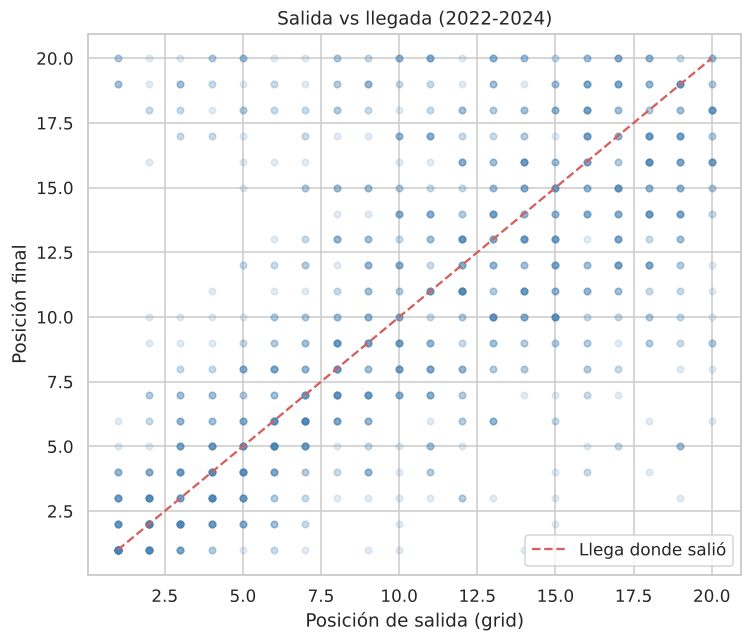

Correlación grid - posición final: 0.62


In [3]:
d = df[df['grid'] > 0]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(d['grid'], d['positionOrder'], alpha=0.15, s=18, color='steelblue')
ax.plot([1, 20], [1, 20], 'r--', label='Llega donde salió')
ax.set_xlabel('Posición de salida (grid)'); ax.set_ylabel('Posición final')
ax.set_title('Salida vs llegada (2022-2024)'); ax.legend()
plt.tight_layout(); plt.savefig('img/01_grid_vs_final.png'); plt.show()
print('Correlación grid - posición final:', round(d['grid'].corr(d['positionOrder']), 3))

## 3. Variables sin fuga de datos

Para cada carrera, la forma del piloto y del equipo se calcula **solo con las carreras anteriores**. Se usa una media móvil exponencial (`ewm`, span = 8) desplazada una carrera (`shift(1)`): da más peso a las carreras recientes y no ve la carrera actual. Esto conserva la idea original de ponderar más lo reciente, pero ahora de forma que el modelo no pueda ver el resultado.

- `grid`: posición de salida.
- `pos_media_piloto`: posición final media reciente del piloto.
- `pts_media_piloto`: puntos medios recientes del piloto.
- `pts_media_equipo`: puntos medios recientes por coche del equipo.
- `tasa_abandono`: proporción de abandonos previos del piloto.
- `ganancia_media`: posiciones ganadas de media (grid - llegada) en carreras previas.
- `round`: número de carrera en la temporada.

El historial del piloto continúa entre temporadas, así que las primeras carreras de 2023 y 2024 ya tienen información del año anterior.

In [4]:
EWM_SPAN = 8
df = df.sort_values(['year', 'round', 'positionOrder']).reset_index(drop=True)
df['ganancia'] = np.where(df['grid'] > 0, df['grid'] - df['positionOrder'], np.nan)

def prev_ewm(s, span=EWM_SPAN):
    return s.shift(1).ewm(span=span, min_periods=1).mean()

g = df.groupby('driverId')
df['pos_media_piloto'] = g['positionOrder'].transform(prev_ewm)
df['pts_media_piloto'] = g['points'].transform(prev_ewm)
df['tasa_abandono']    = g['dnf'].transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
df['ganancia_media']   = g['ganancia'].transform(lambda s: s.shift(1).expanding(min_periods=1).mean())

# Equipo: puntos medios por coche en cada carrera -> media móvil previa
team = (df.groupby(['constructorId', 'year', 'round'], as_index=False)['points'].mean()
          .sort_values(['year', 'round']))
team['pts_media_equipo'] = team.groupby('constructorId')['points'].transform(prev_ewm)
df = df.merge(team[['constructorId', 'year', 'round', 'pts_media_equipo']],
              on=['constructorId', 'year', 'round'])

FEATURES = ['grid', 'pos_media_piloto', 'pts_media_piloto', 'pts_media_equipo',
            'tasa_abandono', 'ganancia_media', 'round']
TARGET = 'positionOrder'

# Filas a modelar: salidas normales. Primera aparición de un piloto/equipo -> valores neutros
data = df[df['grid'] > 0].copy()
neutros = {'pos_media_piloto': 10.5, 'pts_media_piloto': 0.0, 'pts_media_equipo': 0.0,
           'tasa_abandono': 0.1, 'ganancia_media': 0.0}
print('Filas sin historial (primera carrera de cada piloto/equipo):')
print(data[FEATURES].isna().sum()[lambda s: s > 0].to_dict())
data = data.fillna(neutros)
print(f'\nDataset de modelado: {len(data)} filas x {len(FEATURES)} variables')

Filas sin historial (primera carrera de cada piloto/equipo):
{'pos_media_piloto': 28, 'pts_media_piloto': 28, 'pts_media_equipo': 24, 'tasa_abandono': 28, 'ganancia_media': 28}

Dataset de modelado: 1319 filas x 7 variables


## 4. Partición temporal y referencia base

- **Entrenamiento:** 2022-2023.
- **Test:** 2024 (el modelo no lo ve ni para elegir hiperparámetros).
- **Referencia base:** predecir que cada piloto acaba donde salió. Es lo mínimo que un modelo debe superar.

In [5]:
train = data[data['year'] <= 2023]
test  = data[data['year'] == 2024]
print(f'Train (2022-2023): {len(train)} filas | Test (2024): {len(test)} filas')

def metricas(y, p):
    return {'MAE': mean_absolute_error(y, p),
            'RMSE': np.sqrt(mean_squared_error(y, p)),
            'R2': r2_score(y, p)}

y_test = test[TARGET]
base = metricas(y_test, test['grid'])
print('\nReferencia base (llegar donde se salió), test 2024:')
print({k: round(v, 3) for k, v in base.items()})

Train (2022-2023): 851 filas | Test (2024): 468 filas

Referencia base (llegar donde se salió), test 2024:
{'MAE': 2.857, 'RMSE': np.float64(4.191), 'R2': 0.47}


## 5. Modelo: árbol de decisión sobre la **ganancia** de posiciones

Como `grid` ya explica gran parte de la llegada, el árbol no predice la posición directamente, sino cuántas posiciones se ganan o se pierden respecto a la salida (`positionOrder - grid`). La predicción final es `grid + ganancia_predicha`. Así el árbol solo tiene que aprender la desviación respecto a la salida, en lugar de reproducir la identidad con escalones.

Se usa `criterion='absolute_error'`, coherente con evaluar con MAE (el árbol predice la mediana de cada hoja y es menos sensible a las carreras con accidentes).

**Elección de hiperparámetros:** entreno con 2022 y valido con 2023. El test de 2024 no se toca.

In [6]:
ytr_res = train[TARGET] - train['grid']
tr22 = train[train['year'] == 2022]; va23 = train[train['year'] == 2023]

filas = []
for depth in [2, 3, 4, 5, 6]:
    for leaf in [10, 20, 40]:
        m = DecisionTreeRegressor(criterion='absolute_error', max_depth=depth,
                                  min_samples_leaf=leaf, random_state=42)
        m.fit(tr22[FEATURES], tr22[TARGET] - tr22['grid'])
        p = va23['grid'] + m.predict(va23[FEATURES])
        filas.append({'max_depth': depth, 'min_samples_leaf': leaf,
                      'MAE_validacion_2023': mean_absolute_error(va23[TARGET], p)})
busqueda = pd.DataFrame(filas).sort_values('MAE_validacion_2023').reset_index(drop=True)
print('Referencia base en validación 2023:', round(mean_absolute_error(va23[TARGET], va23['grid']), 3))
display(busqueda.head(6).round(3))
mejor = busqueda.iloc[0]
BEST_DEPTH, BEST_LEAF = int(mejor['max_depth']), int(mejor['min_samples_leaf'])
print(f'Elegido: max_depth={BEST_DEPTH}, min_samples_leaf={BEST_LEAF}')

Referencia base en validación 2023: 3.661


,max_depth,min_samples_leaf,MAE_validacion_2023
0,4,10,3.509
1,5,20,3.509
2,6,20,3.509
3,5,10,3.530
4,4,40,3.536
5,5,40,3.536


Elegido: max_depth=4, min_samples_leaf=10


In [7]:
modelo = DecisionTreeRegressor(criterion='absolute_error', max_depth=BEST_DEPTH,
                               min_samples_leaf=BEST_LEAF, random_state=42)
modelo.fit(train[FEATURES], ytr_res)
print(f'Árbol entrenado | profundidad: {modelo.get_depth()} | hojas: {modelo.get_n_leaves()}')

def predecir(modelo, X):
    return X['grid'].values + modelo.predict(X[FEATURES])

Árbol entrenado | profundidad: 4 | hojas: 13


## 6. Evaluación en 2024

Se compara el árbol con la referencia base y con dos modelos más potentes (Random Forest y Gradient Boosting) usando el mismo planteamiento, con hiperparámetros fijos razonables y sin ajustarlos sobre el test.

In [8]:
p_tree = predecir(modelo, test)
rf = RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=10, random_state=42)
rf.fit(train[FEATURES], ytr_res)
gb = GradientBoostingRegressor(loss='absolute_error', max_depth=2, n_estimators=100,
                               learning_rate=0.05, subsample=0.8, random_state=42)
gb.fit(train[FEATURES], ytr_res)

tabla = pd.DataFrame({
    'Base (llega donde salió)':    base,
    'Árbol de decisión':           metricas(y_test, p_tree),
    'Random Forest':               metricas(y_test, predecir(rf, test)),
    'Gradient Boosting':           metricas(y_test, predecir(gb, test)),
}).T
tabla['MAE'] = tabla['MAE'].round(3); tabla['RMSE'] = tabla['RMSE'].round(3); tabla['R2'] = tabla['R2'].round(3)
print('Resultados en el test (temporada 2024):')
display(tabla)

err = np.abs(y_test - np.round(p_tree).clip(1, 20))
err_base = np.abs(y_test - test['grid'])
print()
for k in [0, 1, 2, 3]:
    print(f'Acierta ±{k}: árbol {(err <= k).mean()*100:5.1f}%   |   base {(err_base <= k).mean()*100:5.1f}%')

Resultados en el test (temporada 2024):


,MAE,RMSE,R2
Base (llega donde salió),2.857,4.191,0.470
Árbol de decisión,2.690,3.920,0.536
Random Forest,3.042,3.927,0.535
Gradient Boosting,2.589,3.753,0.575



Acierta ±0: árbol  16.9%   |   base  15.6%
Acierta ±1: árbol  41.2%   |   base  40.2%
Acierta ±2: árbol  59.2%   |   base  60.5%
Acierta ±3: árbol  74.1%   |   base  72.6%


In [9]:
# Error por zona de la parrilla
zona = np.where(test['grid'] <= 10, 'Salida en el top 10', 'Salida fuera del top 10')
comp = pd.DataFrame({'zona': zona,
                     'MAE árbol': np.abs(y_test - p_tree),
                     'MAE base': np.abs(y_test - test['grid'])}).groupby('zona').mean().round(3)
display(comp)

,MAE árbol,MAE base
zona,,
Salida en el top 10,2.492,2.500
Salida fuera del top 10,2.899,3.232


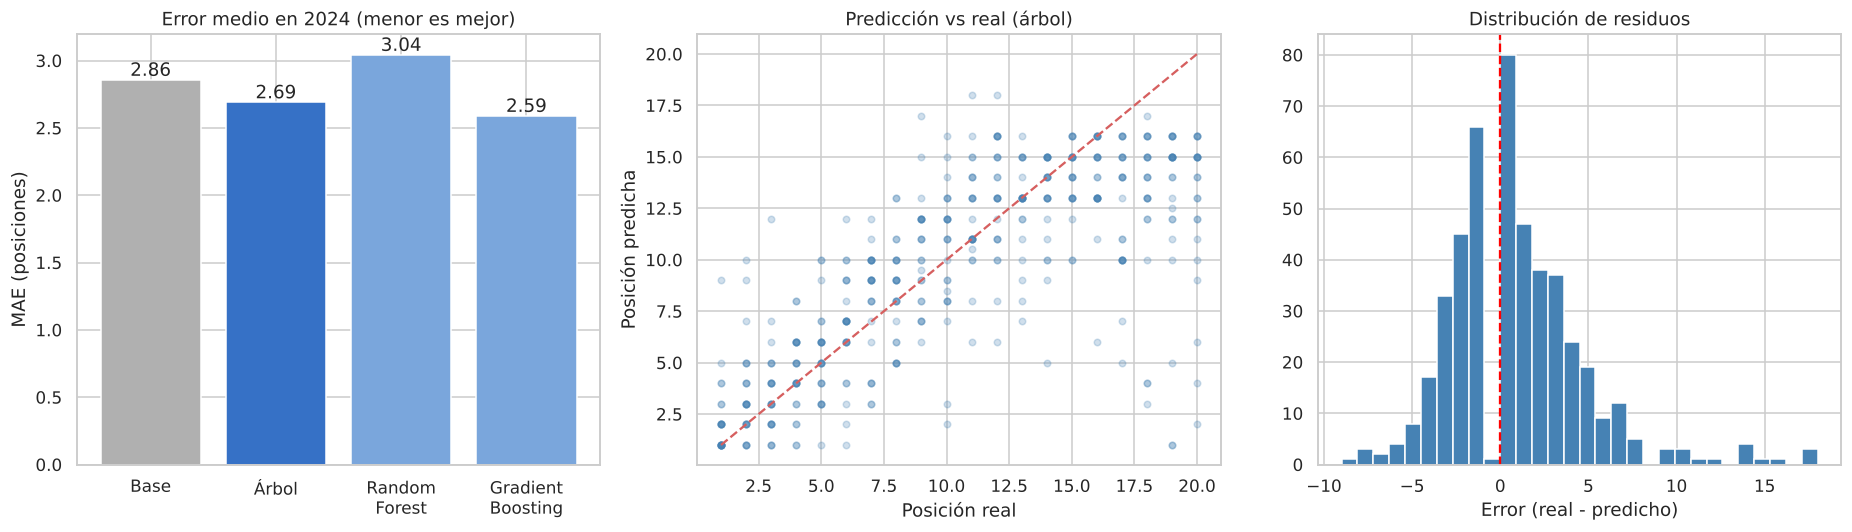

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
nombres = ['Base', 'Árbol', 'Random\nForest', 'Gradient\nBoosting']
maes = tabla['MAE'].values
cols = ['#b0b0b0', '#3671C6', '#7aa6dc', '#7aa6dc']
axes[0].bar(nombres, maes, color=cols, edgecolor='white')
for i, v in enumerate(maes): axes[0].text(i, v + 0.03, f'{v:.2f}', ha='center')
axes[0].set_ylabel('MAE (posiciones)'); axes[0].set_title('Error medio en 2024 (menor es mejor)')

axes[1].scatter(y_test, p_tree, alpha=0.25, s=18, color='steelblue')
axes[1].plot([1, 20], [1, 20], 'r--')
axes[1].set_xlabel('Posición real'); axes[1].set_ylabel('Posición predicha'); axes[1].set_title('Predicción vs real (árbol)')

axes[2].hist(y_test - p_tree, bins=30, color='steelblue', edgecolor='white')
axes[2].axvline(0, color='red', linestyle='--')
axes[2].set_xlabel('Error (real - predicho)'); axes[2].set_title('Distribución de residuos')
plt.tight_layout(); plt.savefig('img/02_evaluacion.png'); plt.show()

## 7. Interpretabilidad del árbol

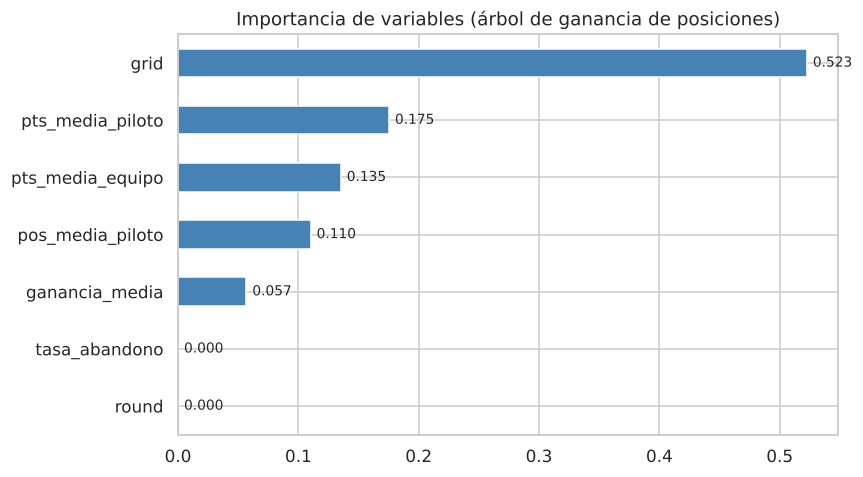

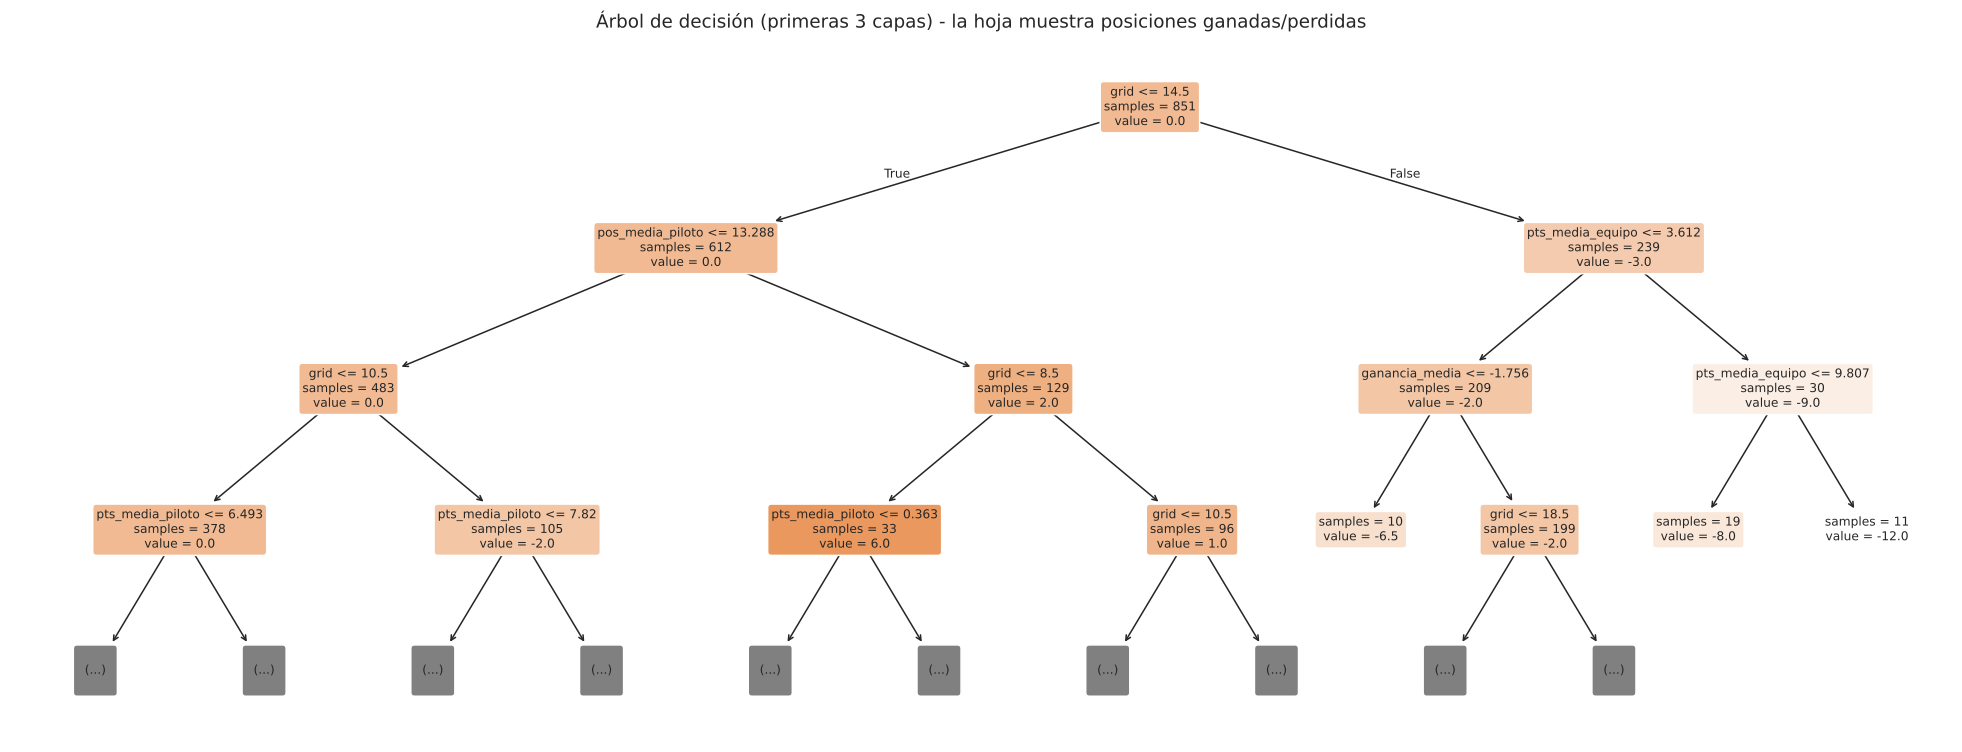

In [11]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
imp.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
for i, v in enumerate(imp): ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_title('Importancia de variables (árbol de ganancia de posiciones)')
plt.tight_layout(); plt.savefig('img/03_importancias.png'); plt.show()

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(modelo, max_depth=3, feature_names=FEATURES, filled=True, rounded=True,
          fontsize=8, ax=ax, impurity=False)
ax.set_title('Árbol de decisión (primeras 3 capas) - la hoja muestra posiciones ganadas/perdidas')
plt.tight_layout(); plt.savefig('img/04_arbol.png'); plt.show()

## 8. Guardado del modelo

In [12]:
# Estado de cada piloto/equipo al terminar 2024 (para predecir 2025)
dfa = df.sort_values(['year', 'round']).copy()   # incluye pit lane en el historial
def ultimo_ewm(s): return s.ewm(span=EWM_SPAN, min_periods=1).mean().iloc[-1]

ga = dfa.groupby('driverId')
estado_pilotos = pd.DataFrame({
    'pos_media_piloto': ga['positionOrder'].apply(ultimo_ewm),
    'pts_media_piloto': ga['points'].apply(ultimo_ewm),
    'tasa_abandono':    ga['dnf'].mean(),
    'ganancia_media':   ga['ganancia'].mean(),
    'grid_medio':       ga['grid'].apply(lambda s: s[s > 0].ewm(span=EWM_SPAN).mean().iloc[-1]),
})
t_all = (dfa.groupby(['constructorId', 'year', 'round'], as_index=False)
            .agg(points=('points', 'mean'), pos=('positionOrder', 'mean'),
                 grid=('grid', lambda x: x[x > 0].mean()))
            .sort_values(['year', 'round']))
gt = t_all.groupby('constructorId')
estado_equipos = pd.DataFrame({'pts_media_equipo': gt['points'].apply(ultimo_ewm),
                               'pos_media_equipo':  gt['pos'].apply(ultimo_ewm),
                               'grid_medio_equipo': gt['grid'].apply(lambda x: x.dropna().ewm(span=EWM_SPAN).mean().iloc[-1])})

joblib.dump(modelo, 'modelo_f1_arbol.pkl')
joblib.dump({'features': FEATURES, 'pilotos': estado_pilotos, 'equipos': estado_equipos,
             'ewm_span': EWM_SPAN}, 'estado_2024.pkl')
print('Guardados: modelo_f1_arbol.pkl y estado_2024.pkl')

Guardados: modelo_f1_arbol.pkl y estado_2024.pkl


## 9. Escenario ilustrativo para 2025

> **Importante:** el dataset llega hasta 2024, así que esta sección **no está validada** contra resultados reales de 2025. Es una simulación que parte del estado de cada piloto a final de 2024 y de una parrilla simplificada de 2025. Sirve para demostrar el modelo, no para medir su acierto. La medida de acierto es la de la sección 6 (test 2024).

Cómo funciona:
- **Pilotos que continúan:** usan su estado a final de 2024.
- **Cambio de equipo:** 60 % historial propio + 40 % del nuevo equipo (puntos, posición media y posición de salida).
- **Rookies:** rendimiento del equipo reducido (pts x 0,7), posición media del equipo + 1,5, abandono 18 %.
- **Simulación:** 24 carreras con ruido en las salidas y en el resultado. Se repite 100 temporadas y se promedian los puntos, para no depender de una sola semilla.

In [13]:
# driverId: (constructorId, cambia_equipo, nombre)
PARRILLA_2025 = {
    830: (9,   False, 'Max Verstappen'),   852: (9,   True,  'Yuki Tsunoda'),
    844: (6,   False, 'Charles Leclerc'),  1:   (6,   True,  'Lewis Hamilton'),
    847: (131, False, 'George Russell'),   846: (1,   False, 'Lando Norris'),
    857: (1,   False, 'Oscar Piastri'),    4:   (117, False, 'Fernando Alonso'),
    840: (117, False, 'Lance Stroll'),     842: (214, False, 'Pierre Gasly'),
    861: (214, True,  'Franco Colapinto'), 848: (3,   False, 'Alexander Albon'),
    832: (3,   True,  'Carlos Sainz'),     807: (15,  True,  'Nico Hülkenberg'),
    839: (210, True,  'Esteban Ocon'),     860: (210, False, 'Oliver Bearman'),
    859: (215, True,  'Liam Lawson'),
}
ROOKIES_2025 = [('Kimi Antonelli', 131), ('Gabriel Bortoleto', 15), ('Isack Hadjar', 215)]

team_names = constructors.set_index('constructorId')['name'].to_dict()
perfiles = []
for did, (cid, cambio, nombre) in PARRILLA_2025.items():
    e = estado_equipos.loc[cid]; p = estado_pilotos.loc[did]
    if cambio:
        pts = 0.6 * p['pts_media_piloto'] + 0.4 * e['pts_media_equipo']
        pos = 0.6 * p['pos_media_piloto'] + 0.4 * e['pos_media_equipo']
        grd = 0.6 * p['grid_medio'] + 0.4 * e['grid_medio_equipo']
    else:
        pts, pos, grd = p['pts_media_piloto'], p['pos_media_piloto'], p['grid_medio']
    perfiles.append(dict(driver=nombre, cid=cid, grid_medio=grd, pos_media_piloto=pos,
                         pts_media_piloto=pts, pts_media_equipo=e['pts_media_equipo'],
                         tasa_abandono=p['tasa_abandono'], ganancia_media=p['ganancia_media']))
for nombre, cid in ROOKIES_2025:
    e = estado_equipos.loc[cid]
    perfiles.append(dict(driver=nombre, cid=cid, grid_medio=e['grid_medio_equipo'] + 1.5,
                         pos_media_piloto=e['pos_media_equipo'] + 1.5,
                         pts_media_piloto=e['pts_media_equipo'] * 0.7, pts_media_equipo=e['pts_media_equipo'],
                         tasa_abandono=0.18, ganancia_media=0.0))
perf = pd.DataFrame(perfiles)
display(perf[['driver', 'pos_media_piloto', 'pts_media_piloto', 'tasa_abandono']].round(2)
        .sort_values('pos_media_piloto').reset_index(drop=True))

,driver,pos_media_piloto,pts_media_piloto,tasa_abandono
0,Charles Leclerc,3.35,15.06,0.13
1,Max Verstappen,3.75,14.95,0.03
2,Lando Norris,4.53,14.05,0.04
3,George Russell,4.68,12.28,0.09
4,Lewis Hamilton,6.05,10.45,0.07
5,Oscar Piastri,6.12,8.71,0.07
6,Kimi Antonelli,7.41,7.21,0.18
7,Carlos Sainz,9.44,7.45,0.15
8,Oliver Bearman,10.08,1.85,0.00
9,Pierre Gasly,10.10,4.80,0.12


In [14]:
PUNTOS = np.array([25, 18, 15, 12, 10, 8, 6, 4, 2, 1] + [0] * 10)
N_CARRERAS, N_SIM = 24, 100
rng = np.random.default_rng(42)
n = len(perf)
total = np.zeros((N_SIM, n))

for s in range(N_SIM):
    for ronda in range(1, N_CARRERAS + 1):
        grid = np.argsort(np.argsort(perf['grid_medio'].values + rng.normal(0, 2.5, n))) + 1
        X = pd.DataFrame({'grid': grid, 'pos_media_piloto': perf['pos_media_piloto'],
                          'pts_media_piloto': perf['pts_media_piloto'],
                          'pts_media_equipo': perf['pts_media_equipo'],
                          'tasa_abandono': perf['tasa_abandono'],
                          'ganancia_media': perf['ganancia_media'], 'round': ronda})
        pred = predecir(modelo, X) + rng.normal(0, 2.0, n)
        pos_final = np.argsort(np.argsort(pred))
        total[s] += PUNTOS[pos_final]

clasif = pd.DataFrame({'Piloto': perf['driver'], 'Equipo': perf['cid'].map(team_names),
                       'Puntos medios predichos': total.mean(axis=0).round(0)})
clasif = clasif.sort_values('Puntos medios predichos', ascending=False).reset_index(drop=True)
clasif.index += 1
print('Clasificación de pilotos (media de 100 temporadas simuladas):')
display(clasif)

constr = (clasif.groupby('Equipo')['Puntos medios predichos'].sum()
                .sort_values(ascending=False).reset_index())
constr.index += 1
print('\nClasificación de constructores:')
display(constr)

Clasificación de pilotos (media de 100 temporadas simuladas):


,Piloto,Equipo,Puntos medios predichos
1,Lando Norris,McLaren,421.0
2,George Russell,Mercedes,352.0
3,Max Verstappen,Red Bull,340.0
4,Oscar Piastri,McLaren,305.0
5,Charles Leclerc,Ferrari,212.0
6,Lewis Hamilton,Ferrari,186.0
7,Kimi Antonelli,Mercedes,146.0
8,Carlos Sainz,Williams,135.0
9,Yuki Tsunoda,Red Bull,98.0
10,Pierre Gasly,Alpine F1 Team,95.0



Clasificación de constructores:


,Equipo,Puntos medios predichos
1,McLaren,726.0
2,Mercedes,498.0
3,Red Bull,438.0
4,Ferrari,398.0
5,Williams,138.0
6,Alpine F1 Team,97.0
7,Aston Martin,80.0
8,Haas F1 Team,27.0
9,Sauber,18.0
10,RB F1 Team,5.0


## 10. Conclusiones y limitaciones

**Resultados (test: temporada 2024, nunca vista en entrenamiento ni en la elección de hiperparámetros):**

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| Referencia base (llega donde salió) | 2,86 | 4,19 | 0,47 |
| **Árbol de decisión** | **2,69** | **3,92** | **0,54** |
| Random Forest | 3,04 | 3,93 | 0,54 |
| Gradient Boosting | 2,59 | 3,75 | 0,58 |

- El árbol mejora la referencia base: reduce el error medio un 6 % (de 2,86 a 2,69 posiciones) y explica más varianza (R² de 0,47 a 0,54).
- La mejora se concentra en los pilotos que salen **fuera del top 10** (MAE 2,90 frente a 3,23). Para quien sale en el top 10 el modelo no mejora la base (2,49 frente a 2,50).
- En porcentaje de aciertos exactos o a ±1/±2 posiciones, árbol y base están prácticamente empatados.
- Gradient Boosting mejora algo más (MAE 2,59), a cambio de perder la interpretabilidad. El Random Forest, con estos parámetros, no mejora al árbol en MAE.

**Lectura honesta:** en la Fórmula 1 la posición de salida ya contiene la mayor parte de la información, y la carrera añade mucho ruido (estrategia, safety cars, accidentes, fiabilidad) que estas variables no capturan. El valor del modelo está en una mejora moderada y consistente, no en predecir con precisión el resultado.

**Qué cambió respecto a la v1:** al eliminar la fuga de datos, las variables que antes dominaban dejaron de "ver" el resultado. La partición temporal da una estimación más realista de lo que ocurriría al predecir una temporada nueva.

**Limitaciones:**
- Solo hay 468 filas de test (una temporada), así que la diferencia de ~0,17 posiciones con la base tiene incertidumbre. Sería recomendable repetir con otras temporadas como test.
- No hay datos de clasificación, clima, estrategia de neumáticos ni fiabilidad del coche.
- La sección 9 (2025) es una simulación ilustrativa, no una validación con resultados reales de 2025.

**Líneas de mejora:** validación con ventana móvil por temporada, incluir años anteriores solo como historial, añadir variables por circuito y comparar con resultados reales de 2025.